# 0a_aquisicao - amostras de treino do TerraClass (Pará) pelo Google Earth Engine

**v2:** pixel central em qualquer posição do polígono e rótulo da vizinhança (`rotulo_x_y`) no CSV. 

Lê `dados\` e grava só em `resultados\0a_aquisicao\`; do projeto atual, apenas lê `landsat_2010.tif` e `mascara_2010.tif`. Monta o conjunto de treino **sem baixar imagens**: o Google Earth Engine (GEE) recorta patches 9×9 de cenas Landsat 5 (Collection 2, nível 2) de 2008 e 2010 no Pará, rotulados pelo TerraClass do mesmo ano, e grava um CSV por cena no Google Drive.

**Antes de rodar**

1. Projeto no Google Cloud registrado no Earth Engine para uso não comercial; `conda install -c conda-forge earthengine-api` no ambiente `cmap`.
2. TerraClass do Pará, 2008 e 2010, em formato matricial (GeoTIFF + `.qml`), em `dados\terraclass\`. O nome de cada arquivo precisa conter o ano.
3. Os dois GeoTIFF enviados ao GEE como assets (Code Editor → Assets → New → Image upload), com **Pyramiding policy = MODE** e o **no-data** que a seção 1 mostrar.


Códigos da nova legenda: F = 1, VS = 2, PA = 3, AG = 4; 9 = fora da legenda; 0 = sem dado do TerraClass.


Obs.: Documentação do Código feita com auxílio de IA (Claude Opus 5.5)

## Parâmetros

In [1]:
# ============================== PARÂMETROS ==============================
PASTA_PROJETO    = r"C:\cmap_ftl\terraclass"                       # tudo o que este notebook grava fica aqui dentro
PASTA_TERRACLASS = rf"{PASTA_PROJETO}\dados\terraclass"            # entrada: GeoTIFF + .qml baixados do portal
PASTA_CSV        = rf"{PASTA_PROJETO}\dados\patches_csv"           # entrada: CSVs baixados do Google Drive (seção 8)
PASTA_SAIDA      = rf"{PASTA_PROJETO}\resultados\0a_aquisicao"     # saída: tabelas e figuras desta etapa
# Somente leitura (projeto atual, nada é gravado lá): grade da área de estudo e conferência
ARQ_IMAGEM_AREA  = r"C:\cmap_ftl\dados_preparados\imagens\landsat_2010.tif"
ARQ_MASCARA_AREA = r"C:\cmap_ftl\dados_preparados\imagens\mascara_2010.tif"

PROJETO_GEE = "cmap-terraclass"                                    # id do projeto no Google Cloud
ASSET_TERRACLASS = {2008: f"projects/{PROJETO_GEE}/assets/terraclass_pa_2008",
                    2010: f"projects/{PROJETO_GEE}/assets/terraclass_pa_2010"}
PASTA_DRIVE = "cmap_terraclass_patches_v2"                         # pasta criada no Google Drive pelas exportações (v2)
COLECAO = "LANDSAT/LT05/C02/T1_L2"                                 # Landsat 5, Collection 2, Tier 1, nível 2

# Cenas
ANOS_TREINO = [2008, 2010]
ORBITA_PONTO_AREA = "227/062"                                      # cena da área de estudo
DATA_AREA_ESTUDO = {2008: "2008-06-23", 2010: "2010-06-29"}        # datas das imagens da área de estudo
ORBITAS_PONTO_EXCLUIDAS = [ORBITA_PONTO_AREA]                      # a cena avaliada não entra no treino
JANELA = ("06-01", "09-30")                                        # mês-dia, inclusive
NUVEM_PREFERIDA = 20                                               # % de nuvem sobre terra (CLOUD_COVER_LAND)
NUVEM_MAXIMA = 40
COBERTURA_MINIMA = 0.02                                            # fração mínima da cena com dado do TerraClass

# Legenda (códigos da nova legenda)
CLASSES = {1: "F", 2: "VS", 3: "PA", 4: "AG"}
CODIGO_FORA = 9
USAR_DESFLORESTAMENTO = False      # True: "Desflorestamento" vira a classe 5 (DS) em vez de ficar fora
CORRECOES_LEGENDA = {}             # depois de revisar a seção 1: {(ano, valor_do_pixel): "F" | "VS" | "PA" | "AG" | "fora"}

# Amostragem
PONTOS_POR_CLASSE = 300            # máximo por classe, por cena e ano
RAIO_PATCH = 4                     # patch 9 x 9
ZONA_EXCLUSAO_M = 10000            # retângulo da área de estudo expandido em 10 km
SEMENTE = 42
CENAS_PILOTO = 3

# Qualidade: os mesmos critérios e valores do 00_preparacao_dados
BANDAS_SR = ["SR_B1", "SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B7"]
BITS_QA_RUINS = [0, 1, 3, 4, 5]    # QA_PIXEL: preenchimento, nuvem dilatada, nuvem, sombra, neve
BITS_SATURACAO = [0, 1, 2, 3, 4, 6]  # QA_RADSAT: bandas 1, 2, 3, 4, 5 e 7
FAIXA_VALIDA_SR = (7273, 43636)
MULT_SR, ADD_SR = 2.75e-05, -0.2   # número digital -> reflectância de superfície

In [2]:
import os, re, json, glob, html, unicodedata, datetime
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import transform as transformar_coords
import matplotlib.pyplot as plt

if not os.path.abspath(PASTA_SAIDA).lower().startswith(os.path.abspath(PASTA_PROJETO).lower() + os.sep):
    raise ValueError(f"PASTA_SAIDA precisa ficar dentro de {PASTA_PROJETO}, para não misturar com os resultados existentes")
os.makedirs(PASTA_SAIDA, exist_ok=True)
if USAR_DESFLORESTAMENTO:
    CLASSES[5] = "DS"
SIGLA_PARA_CODIGO = {sigla: codigo for codigo, sigla in CLASSES.items()}
SIGLA_PARA_CODIGO["fora"] = CODIGO_FORA
ANO_A, ANO_B = min(ANOS_TREINO), max(ANOS_TREINO)
N_LADO = 2 * RAIO_PATCH + 1
print("Classes:", CLASSES, "| fora =", CODIGO_FORA)

Classes: {1: 'F', 2: 'VS', 3: 'PA', 4: 'AG'} | fora = 9


## 1. Legenda do TerraClass

Lê a legenda do arquivo `.qml` de cada ano (valor do pixel → nome da classe) e converte para a nova legenda **pelo nome**, com as regras abaixo, aplicadas nesta ordem. Assim funciona tanto com a legenda original de 2008/2010 (Pasto Limpo, Pasto Sujo...) quanto com a legenda nova do TerraClass (Pastagem Herbácea...).

| Ordem | Se o nome contém | Classe |
|---|---|---|
| 1 | "não floresta" | fora |
| 2 | "solo exposto" | fora |
| 3 | "desflorestamento" | fora (ou DS, se `USAR_DESFLORESTAMENTO`) |
| 4 | "reflorestamento", "silvicultura" | fora |
| 5 | "secundária" | VS |
| 6 | "floresta", "primária" | F |
| 7 | "pasto limpo", "pasto sujo", "regeneração com pasto", "pastagem" | PA |
| 8 | "agricultura anual", "temporária" | AG |
| — | nenhuma das anteriores | fora |



In [ ]:
REGRAS = [
    (["nao floresta"], "fora"),
    (["solo exposto"], "fora"),
    (["desflorestamento"], "DS" if USAR_DESFLORESTAMENTO else "fora"),
    (["reflorestamento", "silvicultura"], "fora"),
    (["secundaria"], "VS"),
    (["floresta", "primaria"], "F"),
    (["pasto limpo", "pasto sujo", "regeneracao com pasto", "pastagem"], "PA"),
    (["agricultura anual", "temporaria"], "AG"),
]

linhas = []
for ano in ANOS_TREINO:
    qmls = glob.glob(os.path.join(PASTA_TERRACLASS, "**", f"*{ano}*.qml"), recursive=True)
    tifs = glob.glob(os.path.join(PASTA_TERRACLASS, "**", f"*{ano}*.tif"), recursive=True)
    if len(qmls) != 1 or len(tifs) != 1:
        raise ValueError(f"{ano}: esperava 1 .qml e 1 .tif com o ano no nome em {PASTA_TERRACLASS}; achei {qmls} e {tifs}")

    # ---- legenda do .qml (renderizador "paletted" ou "singlebandpseudocolor")
    with open(qmls[0], encoding="utf-8", errors="replace") as arq:
        texto = arq.read()
    for entrada in re.findall(r"<(?:paletteEntry|item)\b[^>]*>", texto):
        valor = re.search(r'\bvalue="([^"]*)"', entrada)
        rotulo = re.search(r'\blabel="([^"]*)"', entrada)
        if valor is None or rotulo is None:
            continue
        nome = html.unescape(rotulo.group(1)).strip()
        normal = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode().lower()
        normal = " ".join(normal.split())
        sigla, regra = "fora", "nenhuma regra"
        for palavras, s in REGRAS:
            achou = [p for p in palavras if p in normal]
            if achou:
                sigla, regra = s, f"contém '{achou[0]}'"
                break
        v = int(float(valor.group(1)))
        if (ano, v) in CORRECOES_LEGENDA:
            sigla, regra = CORRECOES_LEGENDA[(ano, v)], "correção manual"
        linhas.append({"ano": ano, "valor": v, "rotulo": nome, "classe": sigla, "regra": regra})

    # ---- conferência do raster 
    with rasterio.open(tifs[0]) as src:
        fator = max(1, max(src.height, src.width) // 2000)
        reduzido = src.read(1, out_shape=(max(1, src.height // fator), max(1, src.width // fator)))
        print(f"{ano}: {os.path.basename(tifs[0])} | CRS {src.crs} | pixel {src.res[0]:.6g} x {src.res[1]:.6g} "
              f"| {src.width} x {src.height} | no-data = {src.nodata}")
        valores_legenda = {l["valor"] for l in linhas if l["ano"] == ano}
        sem_rotulo = [int(v) for v in np.unique(reduzido) if int(v) not in valores_legenda and v != src.nodata]
        if sem_rotulo:
            print(f"   ATENÇÃO: valores no raster sem nome no .qml (vão para 'fora'): {sem_rotulo}")
    if not [l for l in linhas if l["ano"] == ano]:
        raise ValueError(f"{ano}: nenhuma entrada de legenda encontrada em {qmls[0]}")

legenda = pd.DataFrame(linhas).drop_duplicates(["ano", "valor"]).sort_values(["ano", "valor"]).reset_index(drop=True)
legenda["codigo_novo"] = legenda["classe"].map(SIGLA_PARA_CODIGO)
if legenda["codigo_novo"].isna().any():
    raise ValueError(f"Classe desconhecida em CORRECOES_LEGENDA: {sorted(set(legenda.loc[legenda.codigo_novo.isna(), 'classe']))}")
legenda["codigo_novo"] = legenda["codigo_novo"].astype(int)
for ano in ANOS_TREINO:
    faltando = [s for s in CLASSES.values() if s not in set(legenda.loc[legenda.ano == ano, "classe"])]
    if faltando:
        raise ValueError(f"{ano}: nenhuma classe do TerraClass foi associada a {faltando}; confira os nomes e use CORRECOES_LEGENDA")
legenda.to_csv(os.path.join(PASTA_SAIDA, "legenda_terraclass.csv"), index=False, encoding="utf-8-sig")
print()
print(legenda.to_string(index=False))

## 2. Zona de exclusão

Retângulo da área de estudo (lido da grade de `landsat_2010.tif`) expandido em `ZONA_EXCLUSAO_M` para cada lado. Os lados são densificados antes da conversão para coordenadas geográficas, para o polígono no GEE seguir o retângulo da UTM. O GeoJSON pode ser aberto no QGIS.

In [ ]:
with rasterio.open(ARQ_IMAGEM_AREA) as src:
    t_area, crs_area = src.transform, src.crs
    alt_area, larg_area = src.height, src.width
x_min, y_max = t_area.c, t_area.f
x_max, y_min = x_min + larg_area * t_area.a, y_max + alt_area * t_area.e
print(f"Área de estudo: {larg_area} colunas x {alt_area} linhas | {crs_area} | x {x_min:.0f} a {x_max:.0f}, y {y_min:.0f} a {y_max:.0f}")

xa, xb = x_min - ZONA_EXCLUSAO_M, x_max + ZONA_EXCLUSAO_M
ya, yb = y_min - ZONA_EXCLUSAO_M, y_max + ZONA_EXCLUSAO_M
n = 50
xs = list(np.linspace(xa, xb, n)) + [xb] * n + list(np.linspace(xb, xa, n)) + [xa] * n     # anti-horário
ys = [ya] * n + list(np.linspace(ya, yb, n)) + [yb] * n + list(np.linspace(yb, ya, n))
lons, lats = transformar_coords(crs_area, "EPSG:4326", xs, ys)
anel = [[float(lo), float(la)] for lo, la in zip(lons, lats)]
anel.append(anel[0])

zona = {"type": "FeatureCollection",
        "features": [{"type": "Feature",
                      "properties": {"nome": "zona_exclusao", "expansao_m": ZONA_EXCLUSAO_M},
                      "geometry": {"type": "Polygon", "coordinates": [anel]}}]}
with open(os.path.join(PASTA_SAIDA, "zona_exclusao.geojson"), "w", encoding="utf-8") as arq:
    json.dump(zona, arq)
print(f"Zona de exclusão: {(xb - xa) / 1000:.1f} km x {(yb - ya) / 1000:.1f} km | "
      f"lon {min(lons):.4f} a {max(lons):.4f}, lat {min(lats):.4f} a {max(lats):.4f}")

## 3. Conexão com o GEE

Na primeira vez, `ee.Authenticate()` abre o navegador para autorizar; depois, não pede mais. A célula também mostra a projeção e o pixel dos assets do TerraClass.

In [3]:
import ee
ee.Authenticate()
ee.Initialize(project=PROJETO_GEE)

with open(os.path.join(PASTA_SAIDA, "zona_exclusao.geojson"), encoding="utf-8") as arq:
    anel = json.load(arq)["features"][0]["geometry"]["coordinates"][0]
zona_ee = ee.Geometry.Polygon(coords=[anel], geodesic=False)

tc_ee = {}
for ano in ANOS_TREINO:
    tc_ee[ano] = ee.Image(ASSET_TERRACLASS[ano]).select(0)
    proj = tc_ee[ano].projection()
    print(f"{ano}: {ASSET_TERRACLASS[ano]} | {proj.crs().getInfo()} | pixel ~ {proj.nominalScale().getInfo():.1f} m")

2008: projects/cmap-terraclass/assets/terraclass_pa_2008 | EPSG:4674 | pixel ~ 10.0 m
2010: projects/cmap-terraclass/assets/terraclass_pa_2010 | EPSG:4674 | pixel ~ 10.0 m


## 4. Seleção das cenas

**4.1** lista as cenas Tier 1 da janela (1.º de junho a 30 de setembro) que tocam o TerraClass. **4.2** escolhe uma por órbita-ponto e ano: entre as de até `NUVEM_PREFERIDA`% de nuvem sobre terra, a mais próxima da data da imagem da área de estudo daquele ano; sem nenhuma, a menos nublada até `NUVEM_MAXIMA`%; sem nenhuma, a órbita-ponto fica fora naquele ano. A órbita-ponto da área de estudo é excluída. **4.3** mede a fração de cada cena coberta pelo TerraClass (o Pará) e marca `usar = False` nas que quase não têm dado.

Você pode editar a coluna `usar` de `cenas_selecionadas.csv` à mão: a seção 6 lê o arquivo.

In [ ]:
# 4.1 cenas candidatas (GEE)
regiao_busca = tc_ee[ANO_B].geometry()
linhas = []
for ano in ANOS_TREINO:
    fim = ee.Date(f"{ano}-{JANELA[1]}").advance(1, "day")
    colecao = ee.ImageCollection(COLECAO).filterBounds(regiao_busca).filterDate(f"{ano}-{JANELA[0]}", fim)
    lista = colecao.reduceColumns(ee.Reducer.toList(5), ["system:index", "WRS_PATH", "WRS_ROW",
                                                         "CLOUD_COVER_LAND", "system:time_start"]).get("list").getInfo()
    for id_gee, path, row, nuvem, t_ms in lista:
        data = datetime.datetime.fromtimestamp(t_ms / 1000, tz=datetime.timezone.utc).date()
        linhas.append({"ano": ano, "orbita_ponto": f"{int(path):03d}/{int(row):03d}", "path": int(path), "row": int(row),
                       "id_gee": id_gee, "data": data.isoformat(), "nuvem_terra": float(nuvem)})
candidatas = pd.DataFrame(linhas)
candidatas.to_csv(os.path.join(PASTA_SAIDA, "cenas_candidatas.csv"), index=False)
print(f"{len(candidatas)} cenas na janela, em {candidatas['orbita_ponto'].nunique()} órbitas-ponto")

In [ ]:
# 4.2 uma cena por órbita-ponto e ano (só pandas)
candidatas = pd.read_csv(os.path.join(PASTA_SAIDA, "cenas_candidatas.csv"), dtype={"orbita_ponto": str})
cand = candidatas[(candidatas["nuvem_terra"] >= 0) & (~candidatas["orbita_ponto"].isin(ORBITAS_PONTO_EXCLUIDAS))].copy()
alvo = pd.to_datetime(cand["ano"].map(DATA_AREA_ESTUDO))
cand["dias_ate_alvo"] = (pd.to_datetime(cand["data"]) - alvo).dt.days.abs()

escolhidas, sem_cena = [], []
for (ano, op), g in cand.groupby(["ano", "orbita_ponto"]):
    boas = g[g["nuvem_terra"] <= NUVEM_PREFERIDA]
    aceitaveis = g[g["nuvem_terra"] <= NUVEM_MAXIMA]
    if len(boas):
        escolha = boas.sort_values(["dias_ate_alvo", "nuvem_terra"]).iloc[0].to_dict()
        escolha["criterio"] = f"mais próxima da data alvo, nuvem <= {NUVEM_PREFERIDA}%"
    elif len(aceitaveis):
        escolha = aceitaveis.sort_values(["nuvem_terra", "dias_ate_alvo"]).iloc[0].to_dict()
        escolha["criterio"] = f"menos nublada, nuvem <= {NUVEM_MAXIMA}%"
    else:
        sem_cena.append(f"{ano} {op} (menor nuvem: {g['nuvem_terra'].min():.0f}%)")
        continue
    escolhidas.append(escolha)

cenas = pd.DataFrame(escolhidas).sort_values(["ano", "orbita_ponto"]).reset_index(drop=True)
cenas["usar"] = True
cenas.to_csv(os.path.join(PASTA_SAIDA, "cenas_selecionadas.csv"), index=False)
print(cenas.groupby("ano").agg(cenas=("id_gee", "size"), nuvem_media=("nuvem_terra", "mean"),
                               dias_ate_alvo_mediana=("dias_ate_alvo", "median")).round(1).to_string())
print(f"\nExcluídas de propósito: {ORBITAS_PONTO_EXCLUIDAS}")
print(f"Sem cena aceitável ({len(sem_cena)}):", "; ".join(sem_cena) if sem_cena else "nenhuma")

In [ ]:
# 4.3 fração de cada cena coberta pelo TerraClass (GEE; a 1 km, só para triagem)
cenas = pd.read_csv(os.path.join(PASTA_SAIDA, "cenas_selecionadas.csv"), dtype={"orbita_ponto": str})
feicoes = ee.FeatureCollection([ee.Feature(ee.Image(f"{COLECAO}/{i}").geometry(), {"id_gee": i}) for i in cenas["id_gee"]])
res = tc_ee[ANO_B].mask().rename("cobertura").reduceRegions(collection=feicoes, reducer=ee.Reducer.mean(), scale=1000).getInfo()
cobertura = {f["properties"]["id_gee"]: f["properties"].get("mean") for f in res["features"]}
cenas["cobertura_terraclass"] = cenas["id_gee"].map(cobertura).fillna(0).astype(float).round(3)
cenas["usar"] = cenas["usar"] & (cenas["cobertura_terraclass"] >= COBERTURA_MINIMA)
cenas.to_csv(os.path.join(PASTA_SAIDA, "cenas_selecionadas.csv"), index=False)
if (cenas["cobertura_terraclass"] > 0.99).all():
    print("ATENÇÃO: todas as cenas aparecem 100% cobertas; o no-data do asset provavelmente não foi informado no upload.")
print(cenas.groupby("ano")["usar"].agg(["sum", "size"]).rename(columns={"sum": "usadas", "size": "selecionadas"}).to_string())
print(f"\nÓrbitas-ponto distintas em uso: {cenas.loc[cenas['usar'], 'orbita_ponto'].nunique()}")
cenas[["ano", "orbita_ponto", "data", "nuvem_terra", "dias_ate_alvo", "cobertura_terraclass", "usar", "criterio"]]

## 5. Conferência com a imagem de 2010 da área de estudo

Compara, em 5 pixels sorteados da área de estudo, o patch que o GEE entrega com a janela 9×9 de `landsat_2010.tif`. Se os valores baterem, ficam confirmados de uma vez: o mesmo produto (Collection 2, nível 2), o fator de escala, o alinhamento das grades e a **orientação** das colunas do patch. O nome que o GEE dá a cada coluna (`SR_B4_x_y`) diz a posição na janela, mas a documentação não diz o sentido de x e y; a célula 5.3 testa as 8 orientações possíveis e grava a correta em `orientacao_patch.json`, que a Etapa B usa. Esta cena serve só para a conferência: ela não entra no treino.

In [ ]:
# 5.1 pixels da conferência (só computador): janelas 9x9 inteiramente válidas na máscara de 2010
with rasterio.open(ARQ_MASCARA_AREA) as src:
    mascara_area = src.read(1)
with rasterio.open(ARQ_IMAGEM_AREA) as src:
    img_area = src.read().astype(np.float64)
    t_area, crs_area = src.transform, src.crs

rng = np.random.default_rng(SEMENTE)
pontos = []
tentativas = 0
while len(pontos) < 5 and tentativas < 100000:
    tentativas += 1
    r = int(rng.integers(RAIO_PATCH, mascara_area.shape[0] - RAIO_PATCH))
    c = int(rng.integers(RAIO_PATCH, mascara_area.shape[1] - RAIO_PATCH))
    janela_msk = mascara_area[r - RAIO_PATCH:r + RAIO_PATCH + 1, c - RAIO_PATCH:c + RAIO_PATCH + 1]
    janela_img = img_area[:, r - RAIO_PATCH:r + RAIO_PATCH + 1, c - RAIO_PATCH:c + RAIO_PATCH + 1]
    if (janela_msk == 0).all() and np.isfinite(janela_img).all():
        x = t_area.c + (c + 0.5) * t_area.a
        y = t_area.f + (r + 0.5) * t_area.e
        lon, lat = transformar_coords(crs_area, "EPSG:4326", [x], [y])
        pontos.append({"ponto": len(pontos), "linha": r, "coluna": c, "lon": lon[0], "lat": lat[0]})
pontos = pd.DataFrame(pontos)
pontos.to_csv(os.path.join(PASTA_SAIDA, "conferencia_pontos.csv"), index=False)
pontos

In [ ]:
# 5.2 os mesmos pixels no GEE (cena 227/062 da data da imagem da área de estudo)
pontos = pd.read_csv(os.path.join(PASTA_SAIDA, "conferencia_pontos.csv"))
path_area, row_area = [int(p) for p in ORBITA_PONTO_AREA.split("/")]
data_conf = DATA_AREA_ESTUDO[ANO_B]
col_conf = (ee.ImageCollection(COLECAO).merge(ee.ImageCollection(COLECAO.replace("T1_L2", "T2_L2")))
            .filter(ee.Filter.eq("WRS_PATH", path_area)).filter(ee.Filter.eq("WRS_ROW", row_area))
            .filterDate(data_conf, ee.Date(data_conf).advance(1, "day")))
if col_conf.size().getInfo() == 0:
    raise ValueError(f"Cena {ORBITA_PONTO_AREA} de {data_conf} não encontrada no GEE")
img_conf = ee.Image(col_conf.first())
print("Cena no GEE:", img_conf.get("LANDSAT_PRODUCT_ID").getInfo())

patches_conf = img_conf.select(BANDAS_SR).neighborhoodToBands(ee.Kernel.square(RAIO_PATCH))
pts_ee = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([lo, la]), {"ponto": int(k)})
                               for k, lo, la in zip(pontos["ponto"], pontos["lon"], pontos["lat"])])
res = patches_conf.sampleRegions(collection=pts_ee, projection=img_conf.select("SR_B4").projection(), scale=30).getInfo()

linhas = []
for f in res["features"]:
    p = f["properties"]
    for nome, valor in p.items():
        m = re.fullmatch(r"(SR_B\d+)_(-?\d+)_(-?\d+)", nome)
        if m:
            linhas.append({"ponto": p["ponto"], "banda": m.group(1), "x": int(m.group(2)), "y": int(m.group(3)), "nd": valor})
conf = pd.DataFrame(linhas)
conf.to_csv(os.path.join(PASTA_SAIDA, "conferencia_patch.csv"), index=False)
print(f"{conf['ponto'].nunique()} pontos | {len(conf)} valores | x de {conf['x'].min()} a {conf['x'].max()}, "
      f"y de {conf['y'].min()} a {conf['y'].max()}")

In [ ]:
# 5.3 comparação e orientação do patch (só computador)
pontos = pd.read_csv(os.path.join(PASTA_SAIDA, "conferencia_pontos.csv"))
conf = pd.read_csv(os.path.join(PASTA_SAIDA, "conferencia_patch.csv")).merge(pontos[["ponto", "linha", "coluna"]], on="ponto")
with rasterio.open(ARQ_IMAGEM_AREA) as src:
    img_area = src.read().astype(np.float64)
    nomes_local = list(src.descriptions)
if any(n is None for n in nomes_local):
    print("ATENÇÃO: bandas sem nome no GeoTIFF; assumindo a ordem", BANDAS_SR)
    nomes_local = [b.replace("SR_", "") for b in BANDAS_SR]
indice_local = {"SR_" + nome: i for i, nome in enumerate(nomes_local)}
conf["i_banda"] = conf["banda"].map(indice_local)

base = int(min(conf["x"].min(), conf["y"].min()))   # 0 (posições 0..8) ou -RAIO_PATCH (deslocamentos -4..4)
if base not in (0, -RAIO_PATCH):
    raise ValueError(f"Numeração inesperada das colunas do patch (mínimo {base})")
desloc = RAIO_PATCH if base == 0 else 0
dx = conf["x"].to_numpy() - desloc                 # deslocamento em relação ao pixel central
dy = conf["y"].to_numpy() - desloc
refl_gee = conf["nd"].to_numpy() * MULT_SR + ADD_SR

# as 8 orientações possíveis: deslocamento de linha e de coluna em função de (dx, dy)
ORIENTACOES = {"linha=+y, coluna=+x": (0, 1, 1, 0), "linha=-y, coluna=+x": (0, -1, 1, 0),
               "linha=+y, coluna=-x": (0, 1, -1, 0), "linha=-y, coluna=-x": (0, -1, -1, 0),
               "linha=+x, coluna=+y": (1, 0, 0, 1), "linha=-x, coluna=+y": (-1, 0, 0, 1),
               "linha=+x, coluna=-y": (1, 0, 0, -1), "linha=-x, coluna=-y": (-1, 0, 0, -1)}
resultado = []
for nome, (lx, ly, cx, cy) in ORIENTACOES.items():
    lin = conf["linha"].to_numpy() + lx * dx + ly * dy
    col = conf["coluna"].to_numpy() + cx * dx + cy * dy
    refl_local = img_area[conf["i_banda"].to_numpy(), lin, col]
    resultado.append({"orientacao": nome, "dif_max": float(np.max(np.abs(refl_local - refl_gee))),
                      "dif_media": float(np.mean(np.abs(refl_local - refl_gee)))})
resultado = pd.DataFrame(resultado).sort_values("dif_max").reset_index(drop=True)
print(resultado.to_string(index=False))

TOLERANCIA = MULT_SR / 2                          # meio número digital
melhor = resultado.iloc[0]
ok = bool(melhor["dif_max"] <= TOLERANCIA)
lx, ly, cx, cy = ORIENTACOES[melhor["orientacao"]]
orientacao = {"ok": ok, "orientacao": melhor["orientacao"], "dif_max": melhor["dif_max"], "base": base,
              "raio": RAIO_PATCH, "linha": {"x": lx, "y": ly}, "coluna": {"x": cx, "y": cy},
              "regra": "a coluna BANDA_x_y vai para patch[RAIO + linha.x*dx + linha.y*dy, RAIO + coluna.x*dx + coluna.y*dy], "
                       "com dx = x - RAIO e dy = y - RAIO se base = 0, ou dx = x e dy = y se base = -RAIO"}
with open(os.path.join(PASTA_SAIDA, "orientacao_patch.json"), "w", encoding="utf-8") as arq:
    json.dump(orientacao, arq, indent=2, ensure_ascii=False)
if ok:
    print(f"\nOK: valores idênticos com '{melhor['orientacao']}' (diferença máxima {melhor['dif_max']:.2e}).")
else:
    print(f"\nATENÇÃO: nenhuma orientação reproduz a sua imagem (melhor diferença {melhor['dif_max']:.4f}). "
          "Não exporte; me mande as tabelas desta seção.")

## 6. Amostragem e exportação

Mudando `ETAPA`:

1. `"teste"` - uma cena, numa área de 20 km de raio, poucos pontos, resultado na tela. Confere colunas e classes. Não exporta.
2. `"piloto"` - exporta as `CENAS_PILOTO` primeiras cenas. Veja o consumo na seção 7 antes de seguir.
3. `"todas"` - exporta o resto. Cenas já enviadas (registradas em `tarefas_exportacao.csv`) não são reenviadas.

Para cada cena: máscara de qualidade igual à do `00_preparacao_dados`; patch 9×9 inteiramente limpo; TerraClass do mesmo ano convertido para a nova legenda; pixel central em **qualquer posição do polígono, inclusive na borda** (os patches precisam ter bordas, estradas e misturas, como as janelas da imagem inteira que a CNN vai classificar); fora da zona de exclusão; sem a transição proibida (F em 2010 sem F em 2008). O sorteio é estratificado, com até `PONTOS_POR_CLASSE` por classe, e feito **na projeção da própria cena**: a imagem não é reamostrada (o TerraClass é, por vizinho mais próximo).

Junto com o patch da imagem (`SR_Bn_x_y`, 6 × 81 colunas), cada linha leva o **patch do rótulo** (`rotulo_x_y`, 81 colunas: a classe do TerraClass em cada pixel da janela; 0 = sem dado, 9 = fora da legenda). Com ele, a seção 8 mede quantos patches têm borda, e qualquer filtro de borda pode ser testado depois sem exportar de novo.

In [5]:
ETAPA = "todas"          # "teste" -> "piloto" -> "todas"

legenda = pd.read_csv(os.path.join(PASTA_SAIDA, "legenda_terraclass.csv"))
cenas = pd.read_csv(os.path.join(PASTA_SAIDA, "cenas_selecionadas.csv"), dtype={"orbita_ponto": str})
cenas = cenas[cenas["usar"]].reset_index(drop=True)
cenas["arquivo"] = [f"patches_{a}_{p:03d}{r:03d}" for a, p, r in zip(cenas["ano"], cenas["path"], cenas["row"])]
with open(os.path.join(PASTA_SAIDA, "orientacao_patch.json"), encoding="utf-8") as arq:
    orientacao = json.load(arq)
if ETAPA != "teste" and not orientacao["ok"]:
    raise ValueError("A conferência da seção 5 não passou; não exporte.")

arq_log = os.path.join(PASTA_SAIDA, "tarefas_exportacao.csv")
log = pd.read_csv(arq_log) if os.path.exists(arq_log) else pd.DataFrame(
    columns=["arquivo", "ano", "orbita_ponto", "id_gee", "id_tarefa", "enviada_em"])

if ETAPA == "teste":
    rodar = cenas.sort_values("cobertura_terraclass").iloc[[-1]]
elif ETAPA == "piloto":
    rodar = cenas.iloc[:CENAS_PILOTO]
elif ETAPA == "todas":
    rodar = cenas
else:
    raise ValueError("ETAPA deve ser 'teste', 'piloto' ou 'todas'")
if ETAPA != "teste":
    rodar = rodar[~rodar["arquivo"].isin(log["arquivo"])]
print(f"ETAPA = {ETAPA}: {len(rodar)} cena(s)")

# TerraClass na nova legenda (0 = sem dado, 9 = fora) e a transição proibida
classe_ano = {}
for ano in ANOS_TREINO:
    sel = legenda[(legenda["ano"] == ano) & (legenda["codigo_novo"] != CODIGO_FORA)]
    classe_ano[ano] = (tc_ee[ano].remap(sel["valor"].tolist(), sel["codigo_novo"].tolist(), CODIGO_FORA)
                       .unmask(0).rename("classe"))
COD_F = SIGLA_PARA_CODIGO["F"]
incoerente = classe_ano[ANO_B].eq(COD_F).And(classe_ano[ANO_A].neq(COD_F))

kernel_patch = ee.Kernel.square(RAIO_PATCH)
mascara_qa = sum(1 << b for b in BITS_QA_RUINS)
mascara_radsat = sum(1 << b for b in BITS_SATURACAO)
n_colunas_patch = len(BANDAS_SR) * N_LADO * N_LADO

for _, cena in rodar.iterrows():
    ano, path, row = int(cena["ano"]), int(cena["path"]), int(cena["row"])
    img = ee.Image(f"{COLECAO}/{cena['id_gee']}")
    proj = img.select("SR_B4").projection()
    sr = img.select(BANDAS_SR)

    # pixels válidos (mesma regra do 00_preparacao_dados) e patch inteiramente válido
    ruim = img.select("QA_PIXEL").bitwiseAnd(mascara_qa).neq(0)
    saturado = img.select("QA_RADSAT").bitwiseAnd(mascara_radsat).neq(0)
    fora_faixa = sr.lt(FAIXA_VALIDA_SR[0]).Or(sr.gt(FAIXA_VALIDA_SR[1])).reduce(ee.Reducer.anyNonZero())
    valido = ruim.Or(saturado).Or(fora_faixa).Not().unmask(0)
    patch_limpo = valido.reduceNeighborhood(reducer=ee.Reducer.min(), kernel=kernel_patch)

    # pixel central sorteável: classe da legenda (em qualquer posição do polígono), patch limpo, coerente entre os anos
    na_legenda = classe_ano[ano].gte(1).And(classe_ano[ano].lte(max(CLASSES)))
    classe = classe_ano[ano].updateMask(na_legenda.And(patch_limpo).And(incoerente.Not()))

    data_num = int(str(cena["data"]).replace("-", ""))
    pilha = (classe
             .addBands(ee.Image.constant(ano).rename("ano"))
             .addBands(ee.Image.constant(path * 1000 + row).rename("orbita_ponto"))
             .addBands(ee.Image.constant(data_num).rename("data"))
             .addBands(sr.neighborhoodToBands(kernel_patch))
             .addBands(classe_ano[ano].rename("rotulo").neighborhoodToBands(kernel_patch)))

    if ETAPA == "teste":
        regiao = img.geometry().centroid(maxError=30).buffer(20000).difference(right=zona_ee, maxError=30)
        n_pontos = 10
    else:
        regiao = img.geometry().difference(right=zona_ee, maxError=30)
        n_pontos = PONTOS_POR_CLASSE
    semente = SEMENTE + (ano - 2000) * 1000000 + path * 1000 + row
    amostras = pilha.stratifiedSample(numPoints=n_pontos, classBand="classe", region=regiao, scale=30, projection=proj,
                                      seed=semente, dropNulls=True, tileScale=4, geometries=True)

    if ETAPA == "teste":
        inicio = datetime.datetime.now()
        res = amostras.getInfo()
        teste = pd.DataFrame([f["properties"] for f in res["features"]])
        print(f"{cena['arquivo']} ({cena['data']}): {len(teste)} pontos em {(datetime.datetime.now() - inicio).seconds} s")
        if len(teste):
            colunas_patch = [c for c in teste.columns if re.fullmatch(r"SR_B\d+_-?\d+_-?\d+", c)]
            colunas_rotulo = [c for c in teste.columns if re.fullmatch(r"rotulo_-?\d+_-?\d+", c)]
            print("Pontos por classe:", teste["classe"].map(CLASSES).value_counts().to_dict())
            print(f"Colunas do patch: {len(colunas_patch)} (esperado {n_colunas_patch}) | do rótulo: "
                  f"{len(colunas_rotulo)} (esperado {N_LADO * N_LADO}) | outras: "
                  f"{[c for c in teste.columns if c not in colunas_patch and c not in colunas_rotulo]}")
        else:
            print("Nenhum ponto: a área de teste pode estar fora do Pará ou coberta de nuvens; escolha outra cena.")
    else:
        tarefa = ee.batch.Export.table.toDrive(collection=amostras, description=cena["arquivo"], folder=PASTA_DRIVE,
                                               fileNamePrefix=cena["arquivo"], fileFormat="CSV")
        tarefa.start()
        log.loc[len(log)] = [cena["arquivo"], ano, cena["orbita_ponto"], cena["id_gee"], tarefa.id,
                             datetime.datetime.now().isoformat(timespec="seconds")]
        print("enviada:", cena["arquivo"])

if ETAPA != "teste":
    log.to_csv(arq_log, index=False)
    print(f"\n{len(log)} tarefas registradas em {arq_log}")

ETAPA = todas: 113 cena(s)
enviada: patches_2008_222061
enviada: patches_2008_222062
enviada: patches_2008_222063
enviada: patches_2008_223060
enviada: patches_2008_223061
enviada: patches_2008_223062
enviada: patches_2008_223063
enviada: patches_2008_223064
enviada: patches_2008_223065
enviada: patches_2008_223066
enviada: patches_2008_223067
enviada: patches_2008_224060
enviada: patches_2008_224061
enviada: patches_2008_224062
enviada: patches_2008_224063
enviada: patches_2008_224064
enviada: patches_2008_224065
enviada: patches_2008_224066
enviada: patches_2008_224067
enviada: patches_2008_225060
enviada: patches_2008_225061
enviada: patches_2008_225062
enviada: patches_2008_225063
enviada: patches_2008_225064
enviada: patches_2008_225065
enviada: patches_2008_225066
enviada: patches_2008_225067
enviada: patches_2008_226060
enviada: patches_2008_226061
enviada: patches_2008_226062
enviada: patches_2008_226063
enviada: patches_2008_226064
enviada: patches_2008_226065
enviada: patches

## 7. Acompanhamento das tarefas

Mostra o estado de cada exportação e o consumo em EECU (o mesmo que aparece na aba Tasks do Code Editor). Depois do piloto, a última linha estima o consumo de todas as cenas a partir da média das concluídas: compare com a cota mensal do seu projeto (150 EECU-hora no nível Community). Tarefas que falharam ou foram canceladas saem de `tarefas_exportacao.csv`, para a seção 6 reenviá-las na próxima vez com `ETAPA = "todas"`.

In [7]:
arq_log = os.path.join(PASTA_SAIDA, "tarefas_exportacao.csv")
log = pd.read_csv(arq_log)
enviadas = set(log["arquivo"])
linhas, vistos = [], set()
for op in ee.data.listOperations():                 # mais recentes primeiro
    meta = op.get("metadata", {})
    desc = meta.get("description", "")
    if desc in enviadas and desc not in vistos:
        vistos.add(desc)
        linhas.append({"arquivo": desc, "estado": meta.get("state"),
                       "eecu_h": (meta.get("batchEecuUsageSeconds") or 0) / 3600,
                       "inicio": meta.get("startTime"), "fim": meta.get("endTime")})
estado = pd.DataFrame(linhas, columns=["arquivo", "estado", "eecu_h", "inicio", "fim"])
estado.to_csv(os.path.join(PASTA_SAIDA, "estado_tarefas.csv"), index=False)
print(estado["estado"].value_counts().to_string())

concluidas = estado[estado["estado"] == "SUCCEEDED"]
if len(concluidas):
    cenas_uso = pd.read_csv(os.path.join(PASTA_SAIDA, "cenas_selecionadas.csv"))
    n_total = int(cenas_uso["usar"].sum())
    media = concluidas["eecu_h"].mean()
    print(f"\nEECU-hora: {estado['eecu_h'].sum():.2f} até agora | média por cena {media:.3f} | "
          f"estimativa para as {n_total} cenas: {media * n_total:.1f}")

falhas = estado[estado["estado"].isin(["FAILED", "CANCELLED"])]
if len(falhas):
    print("\nFalharam ou foram canceladas (serão reenviadas):", list(falhas["arquivo"]))
    log[~log["arquivo"].isin(falhas["arquivo"])].to_csv(arq_log, index=False)

estado
SUCCEEDED    113

EECU-hora: 51.70 até agora | média por cena 0.458 | estimativa para as 113 cenas: 51.7


## 8. Resumo dos CSVs baixados

Depois que todas as tarefas terminarem, baixe a pasta `PASTA_DRIVE` do Google Drive e extraia os CSVs em `PASTA_CSV`. Esta seção conta os patches por ano, classe e órbita-ponto, aponta arquivos faltando, mede quantos patches têm borda (mais de uma classe na janela) e desenha os pontos.

113 arquivos | 107460 patches | colunas de patch: 486 (esperado 486)
Exportados mas não encontrados em PASTA_CSV: nenhum

Patches por ano e classe:
 sigla      F     VS     PA    AG  total
ano                                    
2008   18900  18900  18129  3519  59448
2010   15000  14700  14700  3612  48012

Órbitas-ponto com patches: 63 | com AG: 16

Patches com borda (a janela 5x5 é a que a CNN usa):
         com borda na janela 3x3 (%)  com borda na janela 5x5 (%)  com borda na janela 9x9 (%)
classe                                                                                       
F                               4.1                          7.6                         13.5
VS                             46.0                         68.2                         85.8
PA                             28.7                         44.7                         63.7
AG                             24.4                         39.2                         57.4
todas                        

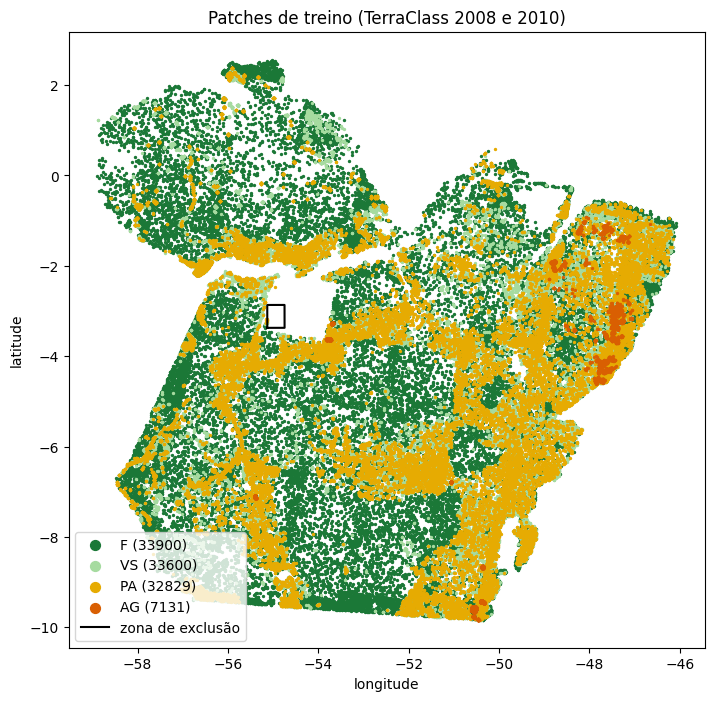

In [9]:
arquivos = sorted(glob.glob(os.path.join(PASTA_CSV, "patches_*.csv")))
partes, vazios, cabecalho = [], [], None
for arq in arquivos:
    try:
        colunas = pd.read_csv(arq, nrows=0).columns
        colunas_rotulo = [c for c in colunas if re.fullmatch(r"rotulo_-?\d+_-?\d+", c)]
        parte = pd.read_csv(arq, usecols=["classe", "ano", "orbita_ponto", ".geo"] + colunas_rotulo)
    except (pd.errors.EmptyDataError, ValueError):       # cena sem nenhum ponto: arquivo vazio ou só com cabeçalho
        vazios.append(os.path.basename(arq))
        continue
    if cabecalho is None:
        cabecalho = colunas
    parte["arquivo"] = os.path.basename(arq)[:-4]
    partes.append(parte)
if not partes:
    raise ValueError(f"Nenhum CSV com patches em {PASTA_CSV}")
if not [c for c in cabecalho if c.startswith("rotulo_")]:
    raise ValueError("Os CSVs não têm o rótulo da vizinhança (rotulo_x_y): são da exportação v1. Use os da pasta v2 do Drive.")
pts = pd.concat(partes, ignore_index=True)
pts["sigla"] = pts["classe"].map(CLASSES)
coords = np.array([json.loads(g)["coordinates"] for g in pts[".geo"]])
pts["lon"], pts["lat"] = coords[:, 0], coords[:, 1]

n_patch = len([c for c in cabecalho if re.fullmatch(r"SR_B\d+_-?\d+_-?\d+", c)])
print(f"{len(arquivos)} arquivos | {len(pts)} patches | colunas de patch: {n_patch} (esperado {len(BANDAS_SR) * N_LADO * N_LADO})")
if vazios:
    print("Arquivos vazios (nenhum ponto na cena):", vazios)
arq_log = os.path.join(PASTA_SAIDA, "tarefas_exportacao.csv")
if os.path.exists(arq_log):
    faltando = sorted(set(pd.read_csv(arq_log)["arquivo"]) - {os.path.basename(a)[:-4] for a in arquivos})
    print("Exportados mas não encontrados em PASTA_CSV:", faltando if faltando else "nenhum")

resumo = pts.pivot_table(index="ano", columns="sigla", values="classe", aggfunc="size", fill_value=0)
resumo = resumo[[s for s in CLASSES.values() if s in resumo.columns]]
resumo["total"] = resumo.sum(axis=1)
print("\nPatches por ano e classe:\n", resumo.to_string())
por_cena = pts.pivot_table(index=["ano", "orbita_ponto"], columns="sigla", values="classe", aggfunc="size", fill_value=0)
por_cena.to_csv(os.path.join(PASTA_SAIDA, "resumo_patches.csv"))
print(f"\nÓrbitas-ponto com patches: {pts['orbita_ponto'].nunique()} | "
      f"com AG: {pts.loc[pts['sigla'] == 'AG', 'orbita_ponto'].nunique()}")

# patches com borda: algum pixel da janela com rótulo diferente do pixel central (outra classe, fora da legenda ou sem dado)
colunas_rotulo = [c for c in cabecalho if re.fullmatch(r"rotulo_-?\d+_-?\d+", c)]
posicoes = np.array([[int(v) for v in c.split("_")[1:]] for c in colunas_rotulo])
if posicoes.min() == 0:                                  # numeração 0..8 -> deslocamento -4..4
    posicoes = posicoes - RAIO_PATCH
rotulos = pts[colunas_rotulo].to_numpy()
centro = pts["classe"].to_numpy()[:, None]
bordas = pd.DataFrame({"classe": pts["sigla"]})
for raio, nome in ((1, "3x3"), (2, "5x5"), (RAIO_PATCH, f"{N_LADO}x{N_LADO}")):
    na_janela = (np.abs(posicoes[:, 0]) <= raio) & (np.abs(posicoes[:, 1]) <= raio)
    bordas[f"com borda na janela {nome} (%)"] = (rotulos[:, na_janela] != centro).any(axis=1) * 100.0
tabela_bordas = bordas.groupby("classe").mean().reindex([s for s in CLASSES.values() if s in set(bordas["classe"])])
tabela_bordas.loc["todas"] = bordas.drop(columns="classe").mean()
tabela_bordas.round(1).to_csv(os.path.join(PASTA_SAIDA, "patches_com_borda.csv"))
print("\nPatches com borda (a janela 5x5 é a que a CNN usa):\n", tabela_bordas.round(1).to_string())

with open(os.path.join(PASTA_SAIDA, "zona_exclusao.geojson"), encoding="utf-8") as arq:
    anel_zona = np.array(json.load(arq)["features"][0]["geometry"]["coordinates"][0])
CORES = {"F": "#1b7837", "VS": "#a6dba0", "PA": "#e6ab02", "AG": "#d95f02", "DS": "#7570b3"}
fig, ax = plt.subplots(figsize=(9, 8))
for sigla in CLASSES.values():
    s = pts[pts["sigla"] == sigla]
    ax.scatter(s["lon"], s["lat"], s=2, c=CORES[sigla], label=f"{sigla} ({len(s)})")
ax.plot(anel_zona[:, 0], anel_zona[:, 1], "k-", lw=1.5, label="zona de exclusão")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect("equal")
ax.legend(markerscale=5, loc="lower left")
ax.set_title("Patches de treino (TerraClass 2008 e 2010)")
fig.savefig(os.path.join(PASTA_SAIDA, "mapa_patches.png"), dpi=150, bbox_inches="tight")
plt.show()